<a href="https://colab.research.google.com/github/MandeGanesh778/datascience-digital-library/blob/main/exp9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset loaded successfully!
Dataset shape: (2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0



Missing values after cleaning:
Income              0
MntWines            0
MntFruits           0
MntMeatProducts     0
MntFishProducts     0
MntSweetProducts    0
MntGoldProds        0
dtype: int64


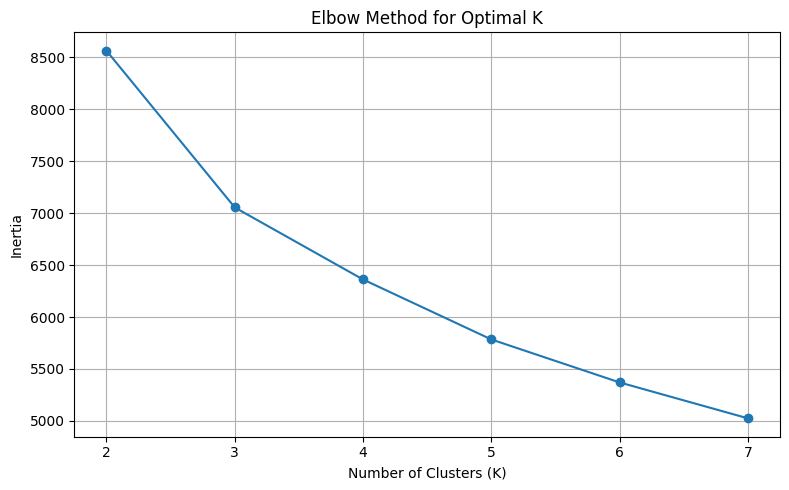


Silhouette Scores:


,Number of Clusters,Silhouette Score
0,2,0.4811
1,3,0.3970
2,4,0.3683
3,5,0.3406
4,6,0.3423
5,7,0.2687


Selected number of clusters: 2

Customer Segment Summary:


,Income,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds
Customer_Segment,,,,,,,
0,41244.22,145.50,7.42,48.00,10.51,7.35,25.19
1,73453.89,610.02,62.77,396.75,89.71,65.16,80.40



Customers in Each Segment:


,Customer Count
Customer_Segment,
0,1476
1,764


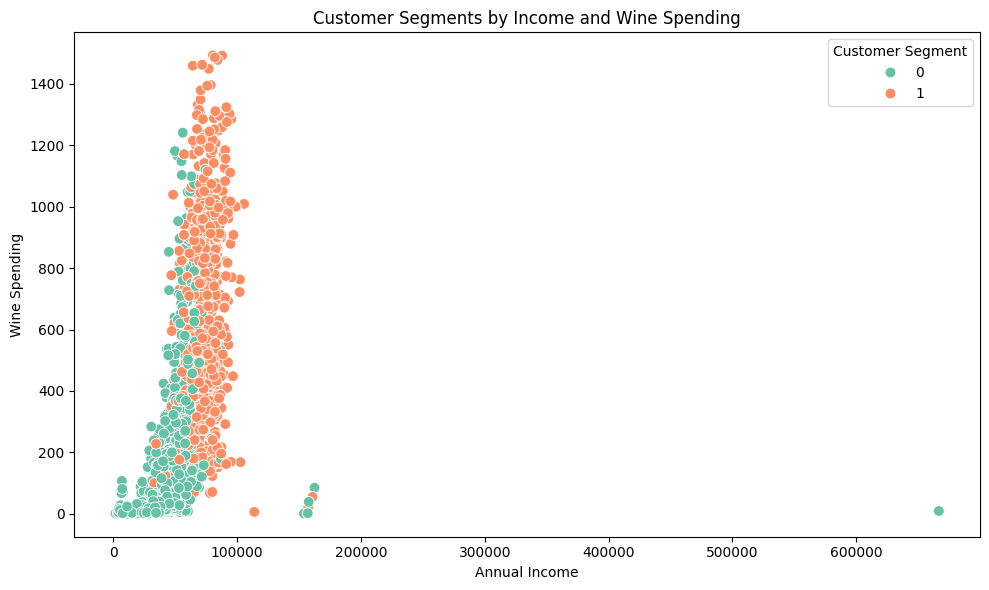

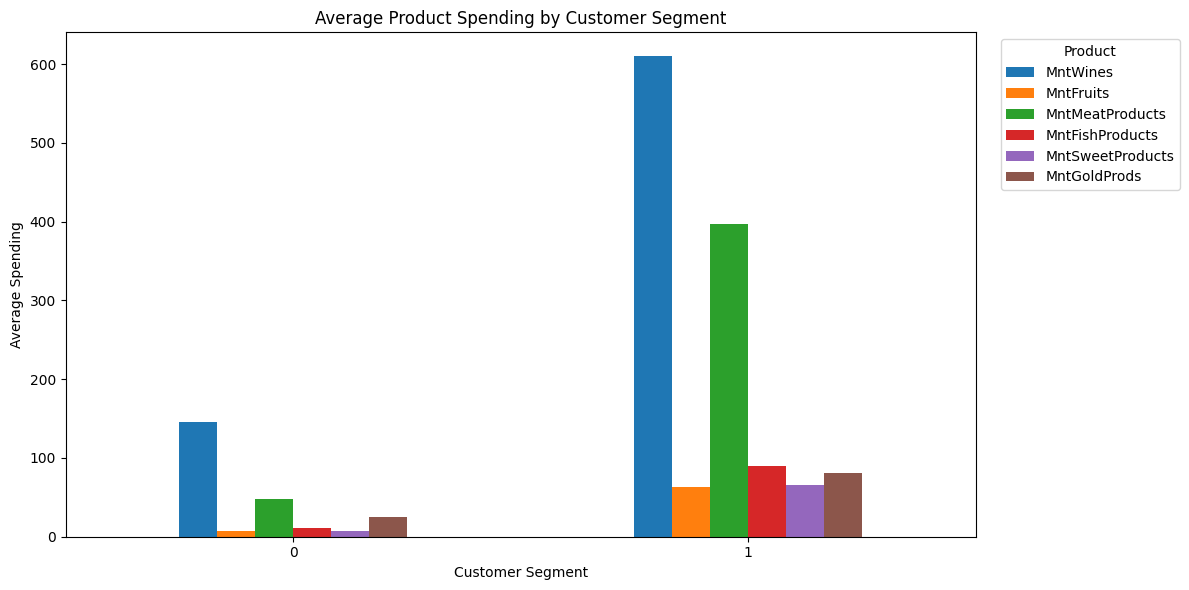

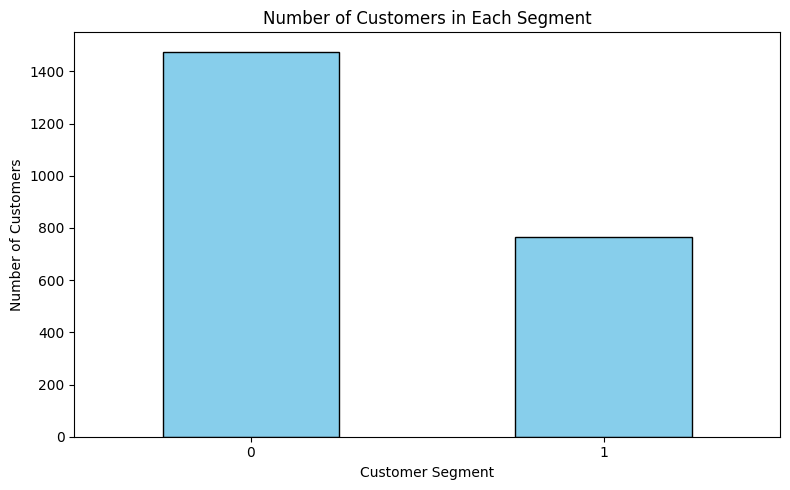


Project completed successfully!
Files created:
1. customer_segments.csv
2. segment_summary.csv
3. silhouette_scores.csv


In [6]:

# CUSTOMER SEGMENTATION USING K-MEANS CLUSTERING

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from IPython.display import display
from google.colab import files

# 1. Download and load the dataset
url = "https://raw.githubusercontent.com/andhikaw789/Customer-Personality-Analysis/main/marketing_campaign.csv"

df = pd.read_csv(url, sep="\t")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

# 2. Select customer features
features = [
    "Income",
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds"
]

# 3. Clean the data
data = df[features].copy()

data = data.replace([np.inf, -np.inf], np.nan)
data = data.fillna(data.median())

data = data.clip(
    lower=data.quantile(0.01),
    upper=data.quantile(0.99),
    axis=1
)

print("\nMissing values after cleaning:")
print(data.isnull().sum())

# 4. Standardize the features
scaler = StandardScaler()
X = scaler.fit_transform(data)

# 5. Find the suitable number of clusters
inertias = []
scores = []
k_values = range(2, 8)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X)

    inertias.append(model.inertia_)
    scores.append(silhouette_score(X, labels))

# Elbow Method Graph
plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal K")
plt.xticks(list(k_values))
plt.grid(True)
plt.tight_layout()
plt.show()

# Silhouette Scores
score_table = pd.DataFrame({
    "Number of Clusters": list(k_values),
    "Silhouette Score": scores
})

print("\nSilhouette Scores:")
display(score_table.round(4))

best_k = list(k_values)[scores.index(max(scores))]
print("Selected number of clusters:", best_k)

# 6. Train the final K-Means model
kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

df["Customer_Segment"] = kmeans.fit_predict(X)

# 7. Analyze customer segments
summary = df.groupby("Customer_Segment")[features].mean().round(2)

print("\nCustomer Segment Summary:")
display(summary)

print("\nCustomers in Each Segment:")
display(df["Customer_Segment"].value_counts().sort_index().to_frame("Customer Count"))

# 8. Visualize customer segments
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Income",
    y="MntWines",
    hue="Customer_Segment",
    palette="Set2",
    s=60
)

plt.title("Customer Segments by Income and Wine Spending")
plt.xlabel("Annual Income")
plt.ylabel("Wine Spending")
plt.legend(title="Customer Segment")
plt.tight_layout()
plt.show()

# 9. Compare product spending by segment
spending_features = [
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds"
]

summary[spending_features].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Average Product Spending by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Spending")
plt.xticks(rotation=0)
plt.legend(
    title="Product",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()

# 10. Display customer segment sizes
segment_counts = df["Customer_Segment"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
segment_counts.plot(kind="bar", color="skyblue", edgecolor="black")
plt.title("Number of Customers in Each Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 11. Save the results
df.to_csv("customer_segments.csv", index=False)
summary.to_csv("segment_summary.csv")
score_table.to_csv("silhouette_scores.csv", index=False)

print("\nProject completed successfully!")
print("Files created:")
print("1. customer_segments.csv")
print("2. segment_summary.csv")
print("3. silhouette_scores.csv")

